# REFMAP laboratory listening test 1 & 2 analysis: Annoyance models

## Setup

In [1]:
# -*- coding: utf-8 -*-
import sys
import os
# Build a path from the notebook's parent directory to the python modules
module_path = os.path.abspath(os.path.join('..'))

# Add to sys.path if not already present
if module_path not in sys.path:
    sys.path.append(module_path)

# import statements
import numpy as np
import pandas as pd
from PyQt5.QtWidgets import QFileDialog, QApplication
from scipy import stats
from scipy import optimize
import warnings
import matplotlib as mpl
from matplotlib import pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import pingouin as pg
from numpy.random import Generator, PCG64
from refmap_psychoacoustics.utils.format_helpers import display_round, round_trad
from refmap_psychoacoustics.modelling import latent_fit, pa_models, general_models
from sklearn import preprocessing, decomposition

In [2]:
# set plot parameters
sns.set_style('white')
mpl.rcParams['font.family'] = 'serif'
mpl.rcParams['font.serif'] = 'Times New Roman'
mpl.rcParams.update({'font.size': 16})
mpl.rcParams['figure.autolayout'] = True
mpl.rcParams['mathtext.fontset'] = 'stix'

SMALL_SIZE = 12
MEDIUM_SIZE = 14
BIGGER_SIZE = 16

plt.rc('font', size=SMALL_SIZE)          # controls default text sizes
plt.rc('axes', titlesize=MEDIUM_SIZE,
       labelsize=MEDIUM_SIZE)    # fontsize of the axes title and x and y labels
plt.rc('xtick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('ytick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('legend', fontsize=SMALL_SIZE)    # legend fontsize
plt.rc('figure', titlesize=BIGGER_SIZE)  # fontsize of the figure title

mycolours = [(0, 102, 255), (0, 204, 153), (255, 0, 102), (74, 111, 152),
             (251, 164, 49), (204, 153, 255), (90, 192, 255), (80, 245, 233),
             (255, 90, 192), (164, 201, 242), (255, 254, 139), (255, 243, 255)]
mycolours = [tuple(shade/255 for shade in colour) for colour in mycolours]

numpy_randomGen = Generator(PCG64(303))

# enable copy-on-write mode for Pandas (will be default from Pandas 3.0)
pd.options.mode.copy_on_write = True

# check/open QApplication instance
if not QApplication.instance():
    app = QApplication(sys.argv)
else:
    app = QApplication.instance() 

# setup ipython autoreloading magic
# %load_ext autoreload
# %autoreload 2

Set the saveplots toggle to True if plot saving is desired:

In [3]:
saveplots=True

if saveplots:
    # select figure output save path
    outFigPath = QFileDialog.getExistingDirectory(caption=r"Select output folder to save plots '03 Experiment\Experiment_1_2\Analysis\Plots'")

    # create subfolders if not already existing
    try:
        os.mkdir(os.path.join(outFigPath, "svg"))
    except FileExistsError:
        pass

    try:
        os.mkdir(os.path.join(outFigPath, "pdf"))
    except FileExistsError:
        pass


In [4]:
savedata = True

if savedata:
    # select data output save path
    outDataPath = QFileDialog.getExistingDirectory(caption=r"Select output folder to save output data in: \03 Experiment\Experiment_1_2\Analysis\Python")


## Functions

### Data splitting

In [7]:
def train_test_split_pandas(df, test_size=0.2, random_state=None):
    # Sample the training data
    train_df = df.sample(frac=1 - test_size, random_state=random_state)
    
    # Drop training rows to get the remaining test data
    test_df = df.drop(train_df.index)
    
    return train_df, test_df

### General goodness-of-fit metrics for prediction models

In [ ]:
def gof(data, predict, dof):
    residuals = data - predict  # residuals
    ss_res = np.sum(residuals**2)  # residual sum of squares
    ss_tot = np.sum((data - np.mean(data))**2)  # total sum of squares
    r_squared = 1 - (ss_res / ss_tot)  # coefficient of determination
    rse = np.sqrt(ss_res / dof)  # residual standard error
    return r_squared, rse

## Import data and organise

In [5]:
# import data
fileExts = "*.csv"

dataByStimTestFilePath = list(QFileDialog.getOpenFileName(filter="refmap_listest1_2_testdataMerge_ByStim.csv",
                                                       caption=r"Open refmap_listest1_2_testdataMerge_ByStim.csv in: \03 Experiment\Experiment_1_2\Analysis\PostProcess"))[0]
dataByStimTest = pd.read_csv(dataByStimTestFilePath, index_col=False)

dataByStimTestNoAmb = dataByStimTest[dataByStimTest['UASEvents'] > 0]


In [9]:
# create new columns normalising key SQMs by loudness
dataByStimTestNoAmb['UASSharpAurSHM05Ex_Nnorm'] = dataByStimTestNoAmb['UASSharpAurSHM05Ex']/dataByStimTestNoAmb['UASLoudECMAPowAvg']
dataByStimTestNoAmb['UASTonalAwSHMInt05Ex_Nnorm'] = dataByStimTestNoAmb['UASTonalAwSHMInt05Ex']/dataByStimTestNoAmb['UASLoudECMAPowAvg']
dataByStimTestNoAmb['UASRoughECMA10Ex_Nnorm'] = dataByStimTestNoAmb['UASRoughECMA10Ex']/dataByStimTestNoAmb['UASLoudECMAPowAvg']

C:\Users\m_lot\AppData\Local\Temp\ipykernel_187776\3730719505.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataByStimTestNoAmb['UASSharpAurSHM05Ex_Nnorm'] = dataByStimTestNoAmb['UASSharpAurSHM05Ex']/dataByStimTestNoAmb['UASLoudECMAPowAvg']
C:\Users\m_lot\AppData\Local\Temp\ipykernel_187776\3730719505.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataByStimTestNoAmb['UASTonalAwSHMInt05Ex_Nnorm'] = dataByStimTestNoAmb['UASTonalAwSHMInt05Ex']/dataByStimTestNoAmb['UASLoudECMAPowAvg']
C:\Users\m_lot\AppData\Local\Temp\ip

In [10]:
# categorise columns

for dataset in [dataByStimTest]:
    dataset['AmbientEnv'] = pd.Categorical(dataset['AmbientEnv'], ["Park", "Residential", "Park (high)",
                                                                   "Highway (low)", "Streetside square",
                                                                   "Highway"])
    dataset['AmbientEnvCore'] = pd.Categorical(dataset['AmbientEnvCore'], ["Park", "Residential",
                                                                           "Streetside square",
                                                                           "Highway"])
    dataset['UASOperation'] = pd.Categorical(dataset['UASOperation'], ["Baseline", "Overflight", "Delivery", "Landing", "Takeoff"])
    dataset['UASType'] = pd.Categorical(dataset['UASType'], ["Baseline", "H520", "M300", "T150"])

for dataset in [dataByStimTestNoAmb]:
    dataset['AmbientEnv'] = pd.Categorical(dataset['AmbientEnv'], ["Park", "Residential", "Park (high)",
                                                                   "Highway (low)", "Streetside square",
                                                                   "Highway"])
    dataset['AmbientEnvCore'] = pd.Categorical(dataset['AmbientEnvCore'], ["Park", "Residential",
                                                                           "Streetside square",
                                                                           "Highway"])
    dataset['UASOperation'] = pd.Categorical(dataset['UASOperation'], ["Overflight", "Delivery", "Landing", "Takeoff"])
    dataset['UASType'] = pd.Categorical(dataset['UASType'], ["H520", "M300", "T150"])


In [11]:
# split into training and test samples
seed = 808
(dataByStimTestNoAmb_train,
 datadataByStimTestNoAmb_train_test) = train_test_split_pandas(dataByStimTestNoAmb,
                                                               test_size=0.2,
                                                               random_state=seed)


## Explore data

In [12]:
# calculate spearman correlation against dAnnoyanceMedian for all metrics

metrics = dataByStimTestNoAmb.columns[dataByStimTestNoAmb.columns.get_loc('PsychAnnoyBoucher') + 1:dataByStimTestNoAmb.columns.get_loc('UASPsychAnnoyBoucher') + 1].to_list()

corr_df = pd.DataFrame(columns=['Metric', 'Spearman_rho', 'p_value'])
for ii, metric in enumerate(metrics):
    testCorr = pg.corr(dataByStimTestNoAmb.loc[:, metric],
                       dataByStimTestNoAmb.loc[:, 'dAnnoyanceMedian'],
                       method='spearman')
    
    corr_df.loc[ii] = [metric, testCorr['r'].iloc[0], testCorr['p_val'].iloc[0]]

print(corr_df.sort_values(by='Spearman_rho', ascending=False).head(10))

metrics_abs = metrics[metrics.index("UASLAeqMaxLR"):]

corr_df_abs = pd.DataFrame(columns=['Metric', 'Spearman_rho', 'p_value'])
for ii, metric in enumerate(metrics_abs):
    testCorr = pg.corr(dataByStimTest.loc[:, metric],
                       dataByStimTest.loc[:, 'dAnnoyanceMedian'],
                       method='spearman')
    
    corr_df_abs.loc[ii] = [metric, testCorr['r'].iloc[0], testCorr['p_val'].iloc[0]]

print(corr_df_abs.sort_values(by='Spearman_rho', ascending=False).head(10))


                     Metric  Spearman_rho       p_value
44  Detect0p5dBIntEx50MaxLR      0.932670  9.843960e-89
7              LAELAF50diff      0.931702  3.797395e-88
18            EPNLLAF50diff      0.929936  4.249651e-87
6              LAELAF90diff      0.928815  1.903651e-86
15            EPNLLAF90diff      0.927840  6.880232e-86
43  Detect0p5dBMaxEx50MaxLR      0.926446  4.183136e-85
35      Detect0p5dBIntMaxLR      0.920914  3.872498e-82
46  Detect0p1dBIntEx50MaxLR      0.920697  5.014653e-82
0             LAeqLAF90diff      0.916807  4.506211e-80
45  Detect0p1dBMaxEx50MaxLR      0.912889  3.365772e-78
                 Metric  Spearman_rho       p_value
17    UASLoudISO3PowAvg      0.736782  1.078234e-36
22  UASLoudQZ5323PowAvg      0.735740  1.522209e-36
16    UASLoudISO1PowAvg      0.734288  2.454414e-36
19  UASLoudQZ5321PowAvg      0.733981  2.714512e-36
24  UASLoudQZ4182PowAvg      0.733200  3.504005e-36
14    UASLoudECMAPowAvg      0.730425  8.617990e-36
1           UASLAEMa

In [13]:
# calculate spearman correlation against dAnnoyanceMedian for all metrics

metrics = dataByStimTest.columns[dataByStimTest.columns.get_loc('AmbLAeqMaxLR'):
                                 dataByStimTest.columns.get_loc('AmbPsychAnnoyBoucher') + 1].to_list()

corr_df = pd.DataFrame(columns=['Metric', 'Spearman_rho', 'p_value'])
for ii, metric in enumerate(metrics):
    testCorr = pg.corr(dataByStimTest.loc[:, metric],
                       dataByStimTest.loc[:, 'dAnnoyanceMean'],
                       method='spearman')
    
    corr_df.loc[ii] = [metric, testCorr['r'].iloc[0], testCorr['p_val'].iloc[0]]

print(corr_df.sort_values(by='Spearman_rho', ascending=False).head(10))


                   Metric  Spearman_rho       p_value
75       AmbImpulsSHM05Ex      0.521409  7.933713e-16
35  AmbTonShpAurSHMPowAvg      0.464231  1.847894e-12
74        AmbImpulsSHMAvg      0.458375  3.779826e-12
73     AmbImpulsSHMPowAvg      0.447060  1.450438e-11
36    AmbTonShpAurSHM05Ex      0.412147  6.815496e-10
66     AmbSharpvBISO105Ex      0.360523  9.493544e-08
64        AmbSharpDIN05Ex      0.360523  9.493544e-08
54         AmbFluctOV10Ex      0.263594  1.242499e-04
70  AmbSharpAurQZ532305Ex      0.251743  2.530766e-04
51       AmbFluctECMA05Ex      0.166506  1.649106e-02


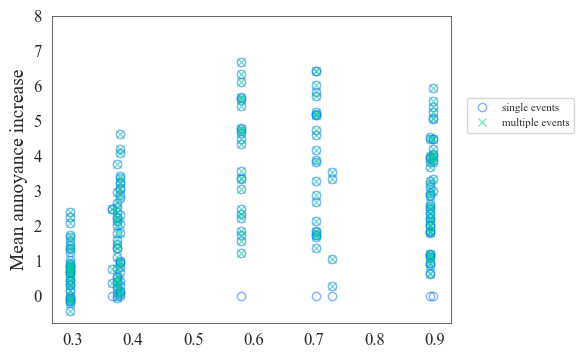

In [14]:

fig, ax = plt.subplots(figsize=(6, 3.75))

testCorr = pg.corr(dataByStimTest.loc[:, 'AmbImpulsSHM05Ex'],
                   dataByStimTest.loc[:, 'dAnnoyanceMedian'],
                   method='spearman')

rVal = display_round(testCorr['r'].iloc[0], 2)
pVal = display_round(testCorr['p_val'].iloc[0], 3)
rCI = testCorr['CI95'].iloc[0]

if testCorr['p_val'].iloc[0] < 0.001:
    equals = ""
else:    
    equals = "="


ax.plot(dataByStimTest.loc[:, 'AmbImpulsSHM05Ex'],
        dataByStimTest.loc[:, 'dAnnoyanceMean'],
        marker='o', markerfacecolor='none', markeredgecolor=mycolours[0], markeredgewidth=1,
        color='none', alpha=0.5, label="single events")

ax.plot(dataByStimTestNoAmb.loc[:, 'AmbImpulsSHM05Ex'],
            dataByStimTestNoAmb.loc[:, 'dAnnoyanceMean'],
            marker='x', markerfacecolor='none', markeredgecolor=mycolours[1], markeredgewidth=1,
            color='none', alpha=0.5, label="multiple events")

ax.set(xlabel=r"",
       ylabel=r"Mean annoyance increase",
    #    xticks=np.arange(-10, 70, 10),
       yticks=np.arange(0, 9, 1))
# ax.text(40.2, -0.05, r"$\rho=$ " + rVal
#         + "\n" + "[" + display_round(rCI[0], 2, floor=False) + ", "
#         + display_round(rCI[1], 2, floor=False) + "]"
#         + "\n" + "(" + "$p" + equals + "$ " + pVal + ")")
# ax.grid(which='both', alpha=0.15, linestyle='--')

ax.legend(loc='upper left', bbox_to_anchor=(1.025, 0.75), fontsize=8)

for axis in ['top','bottom','left','right']:
    ax.spines[axis].set_linewidth(0.5)

# plt.show()

In [125]:
# highly annoyed

corr_dfHA = pd.DataFrame(columns=['Metric', 'Spearman_rho', 'p_value'])
for ii, metric in enumerate(metrics):
    testCorr = pg.corr(dataByStimTestNoAmb.loc[:, metric],
                       dataByStimTestNoAmb.loc[:, 'dHighlyAnnoyedProp'],
                       method='spearman')
    
    corr_dfHA.loc[ii] = [metric, testCorr['r'].iloc[0], testCorr['p_val'].iloc[0]]

print(corr_dfHA.sort_values(by='Spearman_rho', ascending=False).head(20))

corr_dfHA = pd.DataFrame(columns=['Metric', 'Spearman_rho', 'p_value'])
for ii, metric in enumerate(metrics):
    testCorr = pg.corr(dataByStimTestNoAmb.loc[:, metric],
                       dataByStimTestNoAmb.loc[:, 'dHighlyAnnoyedProp'],
                       method='spearman')
    
    corr_dfHA.loc[ii] = [metric, testCorr['r'].iloc[0], testCorr['p_val'].iloc[0]]

print(corr_dfHA.sort_values(by='Spearman_rho', ascending=False).head(20))

                     Metric  Spearman_rho       p_value
165      UASImpulsLoudWZAvg      0.845670  2.390361e-55
108     UASLoudQZ5321PowAvg      0.818488  4.630232e-49
106       UASLoudISO3PowAvg      0.816626  1.141160e-48
105       UASLoudISO1PowAvg      0.815930  1.594107e-48
113     UASLoudQZ4182PowAvg      0.815425  2.030523e-48
111     UASLoudQZ5323PowAvg      0.814517  3.130920e-48
168   UASImpulsLoudWECMAAvg      0.810781  1.813749e-47
175  UASPsychAnnoyWillemsen      0.810364  2.201919e-47
103       UASLoudECMAPowAvg      0.809830  2.818699e-47
171    UASPsychAnnoyWidmann      0.809690  3.007795e-47
112       UASLoudQZ418205Ex      0.808614  4.936400e-47
109       UASLoudQZ532105Ex      0.808239  5.864425e-47
176    UASPsychAnnoyBoucher      0.808072  6.330039e-47
139        UASFluctECMA10Ex      0.807415  8.543868e-47
104         UASLoudISO105Ex      0.807104  9.845020e-47
173         UASPsychAnnoyDi      0.806400  1.355339e-46
110       UASLoudQZ532305Ex      0.806179  1.497

In [23]:
# PCA
metrics = dataByStimTestNoAmb.columns[
    dataByStimTestNoAmb.columns.get_loc('PsychAnnoyBoucher') + 1:
    dataByStimTestNoAmb.columns.get_loc('UASPsychAnnoyBoucher') + 1].to_list() + ['UASSharpAurSHM05Ex_Nnorm', 'UASTonalAwSHMInt05Ex_Nnorm', 'UASRoughECMA10Ex_Nnorm']

data = dataByStimTestNoAmb.loc[:, metrics].copy()
scaled_data = preprocessing.StandardScaler().fit_transform(data)
pca = decomposition.PCA(n_components=5)  # Extract top 5 orthogonal components
pca.fit(scaled_data)
loadings = pd.DataFrame(
    pca.components_.T, 
    columns=['PC1', 'PC2', 'PC3', 'PC4', 'PC5'], 
    index=data.columns
)

print("--- PCA Loadings Matrix ---")
print(loadings.round(3))

--- PCA Loadings Matrix ---
                              PC1    PC2    PC3    PC4    PC5
LAeqLAF90diff               0.086 -0.032 -0.100 -0.072 -0.042
LAeqLAF10diff               0.091 -0.003 -0.036 -0.046 -0.036
LAF10LAF10diff              0.091  0.003 -0.047 -0.030 -0.030
LASmaxLAF90diff             0.084 -0.036 -0.125 -0.044 -0.033
LASmaxLAF50diff             0.080 -0.054 -0.133 -0.033 -0.027
...                           ...    ...    ...    ...    ...
UASPsychAnnoyWillemsen      0.092  0.026  0.075  0.031 -0.042
UASPsychAnnoyBoucher        0.095 -0.000  0.058  0.047 -0.045
UASSharpAurSHM05Ex_Nnorm   -0.086 -0.002 -0.067  0.019  0.108
UASTonalAwSHMInt05Ex_Nnorm  0.002  0.077  0.006 -0.077  0.270
UASRoughECMA10Ex_Nnorm     -0.036 -0.130  0.081  0.067  0.053

[181 rows x 5 columns]


In [27]:
threshold = 1 / np.sqrt(len(data.columns))
print("Threshold: " + f'{threshold}')
important_vars_pc1 = loadings[loadings['PC1'].abs() > threshold]['PC1']
print("\nDominant variables in PC1:\n", important_vars_pc1)
important_vars_pc2 = loadings[loadings['PC2'].abs() > threshold]['PC2']
print("\nDominant variables in PC2:\n", important_vars_pc2)
important_vars_pc3 = loadings[loadings['PC3'].abs() > threshold]['PC3']
print("\nDominant variables in PC3:\n", important_vars_pc3)
important_vars_pc4 = loadings[loadings['PC4'].abs() > threshold]['PC4']
print("\nDominant variables in PC4:\n", important_vars_pc4)
important_vars_pc5 = loadings[loadings['PC5'].abs() > threshold]['PC5']
print("\nDominant variables in PC5:\n", important_vars_pc5)

Threshold: 0.07432941462471664

Dominant variables in PC1:
 LAeqLAF90diff               0.085828
LAeqLAF10diff               0.091203
LAF10LAF10diff              0.090663
LASmaxLAF90diff             0.083733
LASmaxLAF50diff             0.080274
                              ...   
UASPsychAnnoyDi             0.095265
UASPsychAnnoyTorija         0.093380
UASPsychAnnoyWillemsen      0.092112
UASPsychAnnoyBoucher        0.095038
UASSharpAurSHM05Ex_Nnorm   -0.086182
Name: PC1, Length: 109, dtype: float64

Dominant variables in PC2:
 PartSharpAurSHMPowAvg         0.172462
PartSharpAurSHM05Ex           0.142919
PartSharpWidSHMPowAvg         0.169573
PartSharpWidSHM05Ex           0.137610
PartSharpvBSHMPowAvg          0.169183
PartSharpvBSHM05Ex            0.138200
PartTonShpAurSHMPowAvg        0.164093
PartTonShpAurSHM05Ex          0.140849
PartTonShpWidSHMPowAvg        0.162809
PartTonShpWidSHM05Ex          0.134172
PartTonShpvBSHMPowAvg         0.164262
PartTonShpvBSHM05Ex           0.1359

In [28]:
variance_ratios = pca.explained_variance_ratio_

# 2. Get the cumulative variance (running total)
cumulative_variance = np.cumsum(variance_ratios)

print("--- Variance Analysis ---")
for i, (var, cum) in enumerate(zip(variance_ratios, cumulative_variance)):
    print(f"PC{i+1}: Explains {var*100:.1f}% | Cumulative: {cum*100:.1f}%")

--- Variance Analysis ---
PC1: Explains 52.7% | Cumulative: 52.7%
PC2: Explains 13.6% | Cumulative: 66.3%
PC3: Explains 8.4% | Cumulative: 74.7%
PC4: Explains 7.4% | Cumulative: 82.1%
PC5: Explains 3.3% | Cumulative: 85.4%


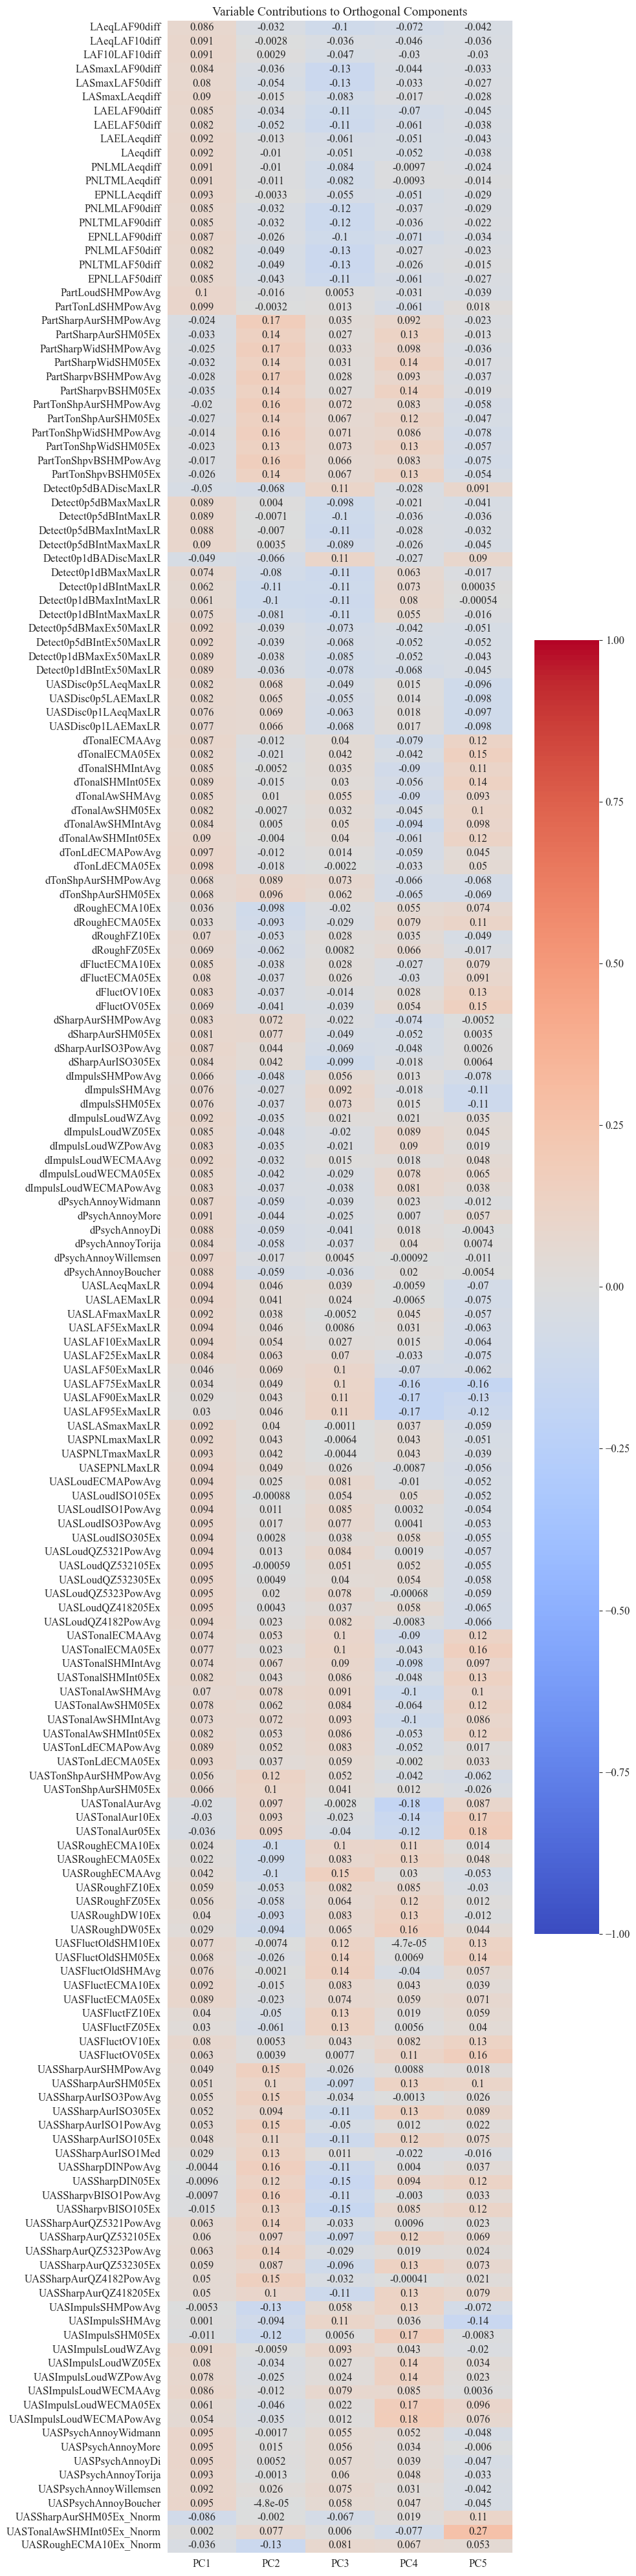

In [29]:
plt.figure(figsize=(10, 40))
sns.heatmap(loadings, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Variable Contributions to Orthogonal Components')
plt.show()

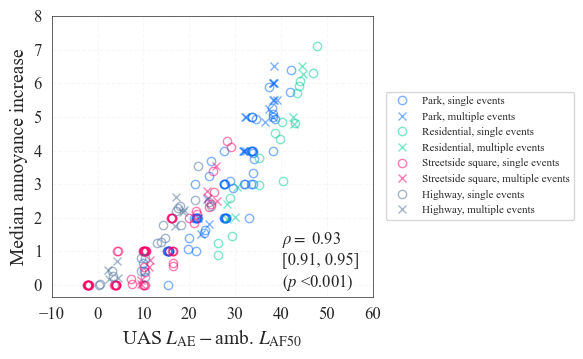

In [13]:
# Generate scatter chart for median change in annoyance, separated colours

fig, ax = plt.subplots(figsize=(6, 3.75))

testCorr = pg.corr(dataByStimTestNoAmb.loc[:, 'LAELAF50diff'],
                   dataByStimTestNoAmb.loc[:, 'dAnnoyanceMedian'],
                   method='spearman')

rVal = display_round(testCorr['r'].iloc[0], 2)
pVal = display_round(testCorr['p_val'].iloc[0], 3)
rCI = testCorr['CI95'].iloc[0]

if testCorr['p_val'].iloc[0] < 0.001:
    equals = ""
else:    
    equals = "="

for ii, ambenv in enumerate(dataByStimTestNoAmb['AmbientEnvCore'].cat.categories):
    ax.plot(dataByStimTestNoAmb.loc[(dataByStimTestNoAmb['AmbientEnvCore'] == ambenv)
                               & (dataByStimTestNoAmb['UASEvents'] == 1), 'LAELAF50diff'],
            dataByStimTestNoAmb.loc[(dataByStimTestNoAmb['AmbientEnvCore'] == ambenv)
                               & (dataByStimTestNoAmb['UASEvents'] == 1), 'dAnnoyanceMedian'],
            marker='o', markerfacecolor='none', markeredgecolor=mycolours[ii], markeredgewidth=1,
            color='none', alpha=0.5, label=ambenv + ", single events")

    ax.plot(dataByStimTestNoAmb.loc[(dataByStimTestNoAmb['AmbientEnvCore'] == ambenv)
                                & (dataByStimTestNoAmb['UASEvents'] > 1), 'LAELAF50diff'],
                dataByStimTestNoAmb.loc[(dataByStimTestNoAmb['AmbientEnvCore'] == ambenv)
                                & (dataByStimTestNoAmb['UASEvents'] > 1), 'dAnnoyanceMedian'],
                marker='x', markerfacecolor='none', markeredgecolor=mycolours[ii], markeredgewidth=1,
                color='none', alpha=0.5, label=ambenv + ", multiple events")

ax.set(xlabel=r"UAS $L_\mathrm{AE} - $amb. $L_\mathrm{AF50}$",
       ylabel=r"Median annoyance increase",
       xticks=np.arange(-10, 70, 10),
       yticks=np.arange(0, 9, 1))
ax.text(40.2, -0.05, r"$\rho=$ " + rVal
        + "\n" + "[" + display_round(rCI[0], 2, floor=False) + ", "
        + display_round(rCI[1], 2, floor=False) + "]"
        + "\n" + "(" + "$p" + equals + "$ " + pVal + ")")
ax.grid(which='both', alpha=0.15, linestyle='--')

ax.legend(loc='upper left', bbox_to_anchor=(1.025, 0.75), fontsize=8)

for axis in ['top','bottom','left','right']:
    ax.spines[axis].set_linewidth(0.5)

if saveplots:
    filename = "DataMeld_dAnnoyMdnLAELAF50diffCorrByAmb"
    plt.savefig(os.path.join(outFigPath, "svg", filename + ".svg"),
                format='svg')
    plt.savefig(os.path.join(outFigPath, "pdf", filename + ".pdf"),
                format='pdf')
plt.show()

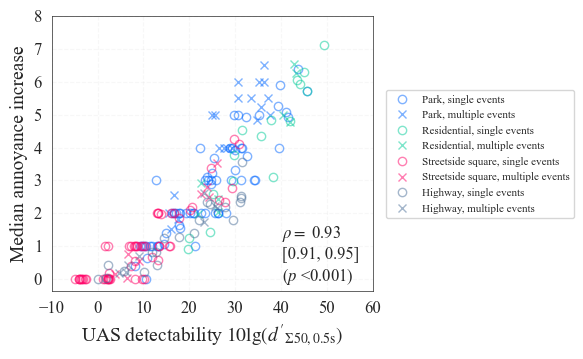

In [ ]:
# Generate scatter chart for median change in annoyance, separated colours

fig, ax = plt.subplots(figsize=(6, 3.75))

testCorr = pg.corr(dataByStimTestNoAmb.loc[:, 'Detect0p5dBIntEx50MaxLR'],
                   dataByStimTestNoAmb.loc[:, 'dAnnoyanceMedian'],
                   method='spearman')

rVal = display_round(testCorr['r'].iloc[0], 2)
pVal = display_round(testCorr['p_val'].iloc[0], 3)
rCI = testCorr['CI95'].iloc[0]

if testCorr['p_val'].iloc[0] < 0.001:
    equals = ""
else:    
    equals = "="

for ii, ambenv in enumerate(dataByStimTestNoAmb['AmbientEnvCore'].cat.categories):
    ax.plot(dataByStimTestNoAmb.loc[(dataByStimTestNoAmb['AmbientEnvCore'] == ambenv)
                               & (dataByStimTestNoAmb['UASEvents'] == 1), 'Detect0p5dBIntEx50MaxLR'],
            dataByStimTestNoAmb.loc[(dataByStimTestNoAmb['AmbientEnvCore'] == ambenv)
                               & (dataByStimTestNoAmb['UASEvents'] == 1), 'dAnnoyanceMedian'],
            marker='o', markerfacecolor='none', markeredgecolor=mycolours[ii], markeredgewidth=1,
            color='none', alpha=0.5, label=ambenv + ", single events")

    ax.plot(dataByStimTestNoAmb.loc[(dataByStimTestNoAmb['AmbientEnvCore'] == ambenv)
                                & (dataByStimTestNoAmb['UASEvents'] > 1), 'Detect0p5dBIntEx50MaxLR'],
                dataByStimTestNoAmb.loc[(dataByStimTestNoAmb['AmbientEnvCore'] == ambenv)
                                & (dataByStimTestNoAmb['UASEvents'] > 1), 'dAnnoyanceMedian'],
                marker='x', markerfacecolor='none', markeredgecolor=mycolours[ii], markeredgewidth=1,
                color='none', alpha=0.5, label=ambenv + ", multiple events")

ax.set(xlabel=r"UAS detectability $10\mathrm{lg}(d'_{\mathrm{\Sigma50,0.5s}})$",
       ylabel=r"Median annoyance increase",
       xticks=np.arange(-10, 70, 10),
       yticks=np.arange(0, 9, 1))
ax.text(40.2, -0.05, r"$\rho=$ " + rVal
        + "\n" + "[" + display_round(rCI[0], 2, floor=False) + ", "
        + display_round(rCI[1], 2, floor=False) + "]"
        + "\n" + "(" + "$p" + equals + "$ " + pVal + ")")
ax.grid(which='both', alpha=0.15, linestyle='--')

ax.legend(loc='upper left', bbox_to_anchor=(1.025, 0.75), fontsize=8)

for axis in ['top','bottom','left','right']:
    ax.spines[axis].set_linewidth(0.5)

if saveplots:
    filename = "DataMeld_dAnnoyMdnDetectCorrByAmb"
    plt.savefig(os.path.join(outFigPath, "svg", filename + ".svg"),
                format='svg')
    plt.savefig(os.path.join(outFigPath, "pdf", filename + ".pdf"),
                format='pdf')
plt.show()

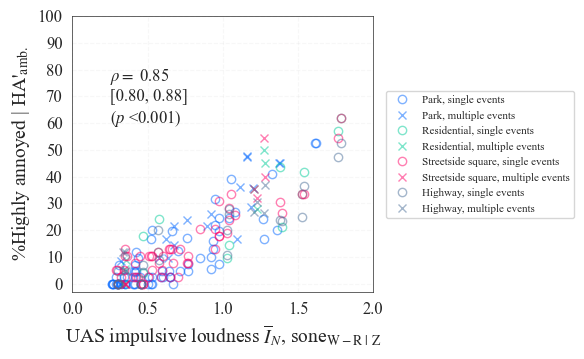

In [104]:
# Generate scatter chart for change in highly annoyed, separated colours

fig, ax = plt.subplots(figsize=(6, 3.75))

testCorr = pg.corr(dataByStimTestNoAmb.loc[:, 'UASImpulsLoudWZAvg'],
                   dataByStimTestNoAmb.loc[:, 'dHighlyAnnoyedProp'],
                   method='spearman')

rVal = display_round(testCorr['r'].iloc[0], 2)
pVal = display_round(testCorr['p_val'].iloc[0], 3)
rCI = testCorr['CI95'].iloc[0]

if testCorr['p_val'].iloc[0] < 0.001:
    equals = ""
else:    
    equals = "="

for ii, ambenv in enumerate(dataByStimTest['AmbientEnvCore'].cat.categories):
    ax.plot(dataByStimTestNoAmb.loc[(dataByStimTestNoAmb['AmbientEnvCore'] == ambenv)
                               & (dataByStimTestNoAmb['UASEvents'] == 1), 'UASImpulsLoudWZAvg'],
            dataByStimTestNoAmb.loc[(dataByStimTestNoAmb['AmbientEnvCore'] == ambenv)
                               & (dataByStimTestNoAmb['UASEvents'] == 1), 'dHighlyAnnoyedProp'],
            marker='o', markerfacecolor='none', markeredgecolor=mycolours[ii], markeredgewidth=1,
            color='none', alpha=0.5, label=ambenv + ", single events")

    ax.plot(dataByStimTestNoAmb.loc[(dataByStimTestNoAmb['AmbientEnvCore'] == ambenv)
                                & (dataByStimTestNoAmb['UASEvents'] > 1), 'UASImpulsLoudWZAvg'],
                dataByStimTestNoAmb.loc[(dataByStimTestNoAmb['AmbientEnvCore'] == ambenv)
                                & (dataByStimTestNoAmb['UASEvents'] > 1), 'dHighlyAnnoyedProp'],
                marker='x', markerfacecolor='none', markeredgecolor=mycolours[ii], markeredgewidth=1,
                color='none', alpha=0.5, label=ambenv + ", multiple events")

ax.set(xlabel=r"UAS impulsive loudness $\overline{I}_{N}$, sone$_\mathrm{W-R\ |\ Z}$",
       ylabel=r"%Highly annoyed | HA'$_\mathrm{amb.}$",
       xticks=np.arange(0, 2.1, 0.5),
       yticks=np.arange(0, 1.1, 0.1),
       yticklabels=[f"{int(y*100)}" for y in np.arange(0, 1.1, 0.1)])
ax.text(0.25, 0.6, r"$\rho=$ " + rVal
        + "\n" + "[" + display_round(rCI[0], 2, floor=False) + ", "
        + display_round(rCI[1], 2, floor=False) + "]"
        + "\n" + "(" + "$p" + equals + "$ " + pVal + ")")
ax.grid(which='both', alpha=0.15, linestyle='--')

ax.legend(loc='upper left', bbox_to_anchor=(1.025, 0.75), fontsize=8)

for axis in ['top','bottom','left','right']:
    ax.spines[axis].set_linewidth(0.5)

if saveplots:
    filename = "DataMeld_dHiAnnoyPropImpulsLdCorrByAmb"
    plt.savefig(os.path.join(outFigPath, "svg", filename + ".svg"),
                format='svg')
    plt.savefig(os.path.join(outFigPath, "pdf", filename + ".pdf"),
                format='pdf')
plt.show()

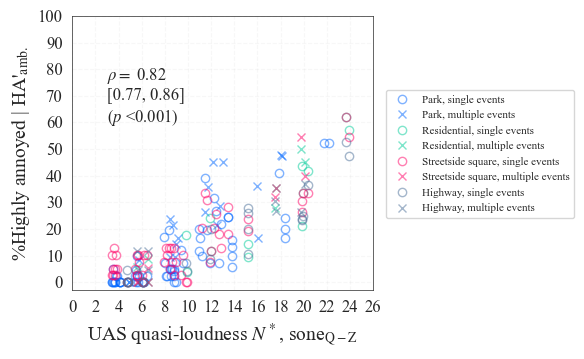

In [16]:
# Generate scatter chart for change in highly annoyed, separated colours

fig, ax = plt.subplots(figsize=(6, 3.75))

testCorr = pg.corr(dataByStimTestNoAmb.loc[:, 'UASLoudQZ5321PowAvg'],
                   dataByStimTestNoAmb.loc[:, 'dHighlyAnnoyedProp'],
                   method='spearman')

rVal = display_round(testCorr['r'].iloc[0], 2)
pVal = display_round(testCorr['p_val'].iloc[0], 3)
rCI = testCorr['CI95'].iloc[0]

if testCorr['p_val'].iloc[0] < 0.001:
    equals = ""
else:    
    equals = "="

for ii, ambenv in enumerate(dataByStimTestNoAmb['AmbientEnvCore'].cat.categories):
    ax.plot(dataByStimTestNoAmb.loc[(dataByStimTestNoAmb['AmbientEnvCore'] == ambenv)
                               & (dataByStimTestNoAmb['UASEvents'] == 1), 'UASLoudQZ5321PowAvg'],
            dataByStimTestNoAmb.loc[(dataByStimTestNoAmb['AmbientEnvCore'] == ambenv)
                               & (dataByStimTestNoAmb['UASEvents'] == 1), 'dHighlyAnnoyedProp'],
            marker='o', markerfacecolor='none', markeredgecolor=mycolours[ii], markeredgewidth=1,
            color='none', alpha=0.5, label=ambenv + ", single events")

    ax.plot(dataByStimTestNoAmb.loc[(dataByStimTestNoAmb['AmbientEnvCore'] == ambenv)
                                & (dataByStimTestNoAmb['UASEvents'] > 1), 'UASLoudQZ5321PowAvg'],
                dataByStimTestNoAmb.loc[(dataByStimTestNoAmb['AmbientEnvCore'] == ambenv)
                                & (dataByStimTestNoAmb['UASEvents'] > 1), 'dHighlyAnnoyedProp'],
                marker='x', markerfacecolor='none', markeredgecolor=mycolours[ii], markeredgewidth=1,
                color='none', alpha=0.5, label=ambenv + ", multiple events")

ax.set(xlabel=r"UAS quasi-loudness $N^*$, sone$_\mathrm{Q-Z}$",
       ylabel=r"%Highly annoyed | HA'$_\mathrm{amb.}$",
       xticks=np.arange(0, 26.1, 2),
       yticks=np.arange(0, 1.1, 0.1),
       yticklabels=[f"{int(y*100)}" for y in np.arange(0, 1.1, 0.1)])
ax.text(3, 0.6, r"$\rho=$ " + rVal
        + "\n" + "[" + display_round(rCI[0], 2, floor=False) + ", "
        + display_round(rCI[1], 2, floor=False) + "]"
        + "\n" + "(" + "$p" + equals + "$ " + pVal + ")")
ax.grid(which='both', alpha=0.15, linestyle='--')

ax.legend(loc='upper left', bbox_to_anchor=(1.025, 0.75), fontsize=8)

for axis in ['top','bottom','left','right']:
    ax.spines[axis].set_linewidth(0.5)

if saveplots:
    filename = "DataMeld_dHiAnnoyPropQZLoud5321CorrByAmb"
    plt.savefig(os.path.join(outFigPath, "svg", filename + ".svg"),
                format='svg')
    plt.savefig(os.path.join(outFigPath, "pdf", filename + ".pdf"),
                format='pdf')
plt.show()

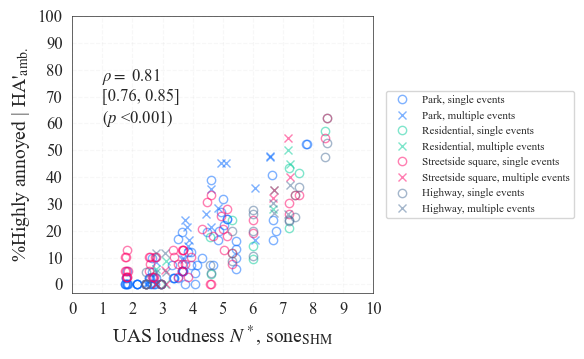

In [ ]:
# Generate scatter chart for change in highly annoyed, separated colours

fig, ax = plt.subplots(figsize=(6, 3.75))

testCorr = pg.corr(dataByStimTestNoAmb.loc[:, 'UASLoudECMAPowAvg'],
                   dataByStimTestNoAmb.loc[:, 'dHighlyAnnoyedProp'],
                   method='spearman')

rVal = display_round(testCorr['r'].iloc[0], 2)
pVal = display_round(testCorr['p_val'].iloc[0], 3)
rCI = testCorr['CI95'].iloc[0]

if testCorr['p_val'].iloc[0] < 0.001:
    equals = ""
else:    
    equals = "="

for ii, ambenv in enumerate(dataByStimTestNoAmb['AmbientEnvCore'].cat.categories):
    ax.plot(dataByStimTestNoAmb.loc[(dataByStimTestNoAmb['AmbientEnvCore'] == ambenv)
                               & (dataByStimTestNoAmb['UASEvents'] == 1), 'UASLoudECMAPowAvg'],
            dataByStimTestNoAmb.loc[(dataByStimTestNoAmb['AmbientEnvCore'] == ambenv)
                               & (dataByStimTestNoAmb['UASEvents'] == 1), 'dHighlyAnnoyedProp'],
            marker='o', markerfacecolor='none', markeredgecolor=mycolours[ii], markeredgewidth=1,
            color='none', alpha=0.5, label=ambenv + ", single events")

    ax.plot(dataByStimTestNoAmb.loc[(dataByStimTestNoAmb['AmbientEnvCore'] == ambenv)
                                & (dataByStimTestNoAmb['UASEvents'] > 1), 'UASLoudECMAPowAvg'],
                dataByStimTestNoAmb.loc[(dataByStimTestNoAmb['AmbientEnvCore'] == ambenv)
                                & (dataByStimTestNoAmb['UASEvents'] > 1), 'dHighlyAnnoyedProp'],
                marker='x', markerfacecolor='none', markeredgecolor=mycolours[ii], markeredgewidth=1,
                color='none', alpha=0.5, label=ambenv + ", multiple events")

ax.set(xlabel=r"UAS loudness $N^*$, sone$_\mathrm{SHM}$",
       ylabel=r"%Highly annoyed | HA'$_\mathrm{amb.}$",
       xticks=np.arange(0, 10.1, 1),
       yticks=np.arange(0, 1.1, 0.1),
       yticklabels=[f"{int(y*100)}" for y in np.arange(0, 1.1, 0.1)])
ax.text(1, 0.6, r"$\rho=$ " + rVal
        + "\n" + "[" + display_round(rCI[0], 2, floor=False) + ", "
        + display_round(rCI[1], 2, floor=False) + "]"
        + "\n" + "(" + "$p" + equals + "$ " + pVal + ")")
ax.grid(which='both', alpha=0.15, linestyle='--')

ax.legend(loc='upper left', bbox_to_anchor=(1.025, 0.75), fontsize=8)

for axis in ['top','bottom','left','right']:
    ax.spines[axis].set_linewidth(0.5)

if saveplots:
    filename = "DataMeld_dHiAnnoyPropLoudECMACorrByAmb"
    plt.savefig(os.path.join(outFigPath, "svg", filename + ".svg"),
                format='svg')
    plt.savefig(os.path.join(outFigPath, "pdf", filename + ".pdf"),
                format='pdf')
plt.show()

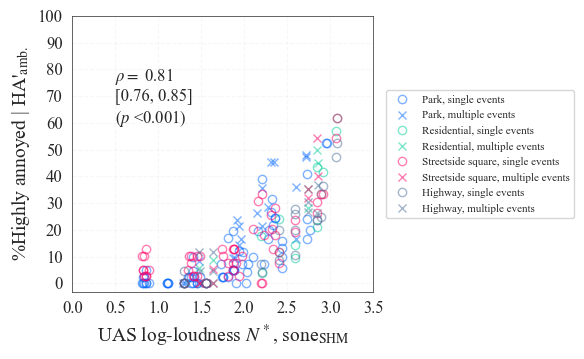

In [24]:
# Generate scatter chart for change in highly annoyed, separated colours

fig, ax = plt.subplots(figsize=(6, 3.75))

testCorr = pg.corr(np.log2(dataByStimTestNoAmb.loc[:, 'UASLoudECMAPowAvg']),
                   dataByStimTestNoAmb.loc[:, 'dHighlyAnnoyedProp'],
                   method='spearman')

rVal = display_round(testCorr['r'].iloc[0], 2)
pVal = display_round(testCorr['p_val'].iloc[0], 3)
rCI = testCorr['CI95'].iloc[0]

if testCorr['p_val'].iloc[0] < 0.001:
    equals = ""
else:    
    equals = "="

for ii, ambenv in enumerate(dataByStimTestNoAmb['AmbientEnvCore'].cat.categories):
    ax.plot(np.log2(dataByStimTestNoAmb.loc[(dataByStimTestNoAmb['AmbientEnvCore'] == ambenv)
                               & (dataByStimTestNoAmb['UASEvents'] == 1), 'UASLoudECMAPowAvg']),
            dataByStimTestNoAmb.loc[(dataByStimTestNoAmb['AmbientEnvCore'] == ambenv)
                               & (dataByStimTestNoAmb['UASEvents'] == 1), 'dHighlyAnnoyedProp'],
            marker='o', markerfacecolor='none', markeredgecolor=mycolours[ii], markeredgewidth=1,
            color='none', alpha=0.5, label=ambenv + ", single events")

    ax.plot(np.log2(dataByStimTestNoAmb.loc[(dataByStimTestNoAmb['AmbientEnvCore'] == ambenv)
                                & (dataByStimTestNoAmb['UASEvents'] > 1), 'UASLoudECMAPowAvg']),
                dataByStimTestNoAmb.loc[(dataByStimTestNoAmb['AmbientEnvCore'] == ambenv)
                                & (dataByStimTestNoAmb['UASEvents'] > 1), 'dHighlyAnnoyedProp'],
                marker='x', markerfacecolor='none', markeredgecolor=mycolours[ii], markeredgewidth=1,
                color='none', alpha=0.5, label=ambenv + ", multiple events")

ax.set(xlabel=r"UAS log-loudness $N^*$, sone$_\mathrm{SHM}$",
       ylabel=r"%Highly annoyed | HA'$_\mathrm{amb.}$",
       xticks=np.arange(0, 3.6, 0.5),
       yticks=np.arange(0, 1.1, 0.1),
       yticklabels=[f"{int(y*100)}" for y in np.arange(0, 1.1, 0.1)])
ax.text(0.5, 0.6, r"$\rho=$ " + rVal
        + "\n" + "[" + display_round(rCI[0], 2, floor=False) + ", "
        + display_round(rCI[1], 2, floor=False) + "]"
        + "\n" + "(" + "$p" + equals + "$ " + pVal + ")")
ax.grid(which='both', alpha=0.15, linestyle='--')

ax.legend(loc='upper left', bbox_to_anchor=(1.025, 0.75), fontsize=8)

for axis in ['top','bottom','left','right']:
    ax.spines[axis].set_linewidth(0.5)

if saveplots:
    filename = "DataMeld_dHiAnnoyPropLogLoudECMACorrByAmb"
    plt.savefig(os.path.join(outFigPath, "svg", filename + ".svg"),
                format='svg')
    plt.savefig(os.path.join(outFigPath, "pdf", filename + ".pdf"),
                format='pdf')
plt.show()

## Cross-validate models

## Psychoacoustic annoyance models


In [30]:
PRED_PA_CHANGE = dict(loud="PartLoudSHMPowAvg", sharp="PartSharpAurSHM05Ex", tonal="dTonalECMAAvg",
                   rough="dRoughECMA10Ex", fluctuation="dFluctECMA10Ex", impulsive="dImpulsSHMAvg")
PRED_PA_ABS = dict(loud="UASLoudECMAPowAvg", sharp="UASSharpAurSHM05Ex", tonal="UASTonalECMAAvg",
               rough="UASRoughECMA10Ex", fluctuation="UASFluctECMA10Ex", impulsive="UASImpulsSHMAvg")

PA_ABS = dict(df=dataByStimTestNoAmb, predictors=PRED_PA_ABS, lower=0, upper=10)
PA_CHANGE = dict(df=dataByStimTestNoAmb, predictors=PRED_PA_CHANGE, lower=0, upper=10)
PA_HA_ABS = dict(df=dataByStimTestNoAmb, predictors=PRED_PA_ABS, lower=0, upper=1)

RESPONSES_PA = {
    "annoy_pa_change_median": dict(PA_CHANGE, obs="AnnoyanceMedian", se="AnnoyanceMedianSE"),
    "dannoy_pa_change_median":    dict(PA_CHANGE, obs="dAnnoyanceMedian", se="dAnnoyanceMedianSE"),
    "dannoy_pa_abs_median":    dict(PA_ABS, obs="dAnnoyanceMedian", se="dAnnoyanceMedianSE"),
    "ha_abs_pa_prop":          dict(PA_HA_ABS, obs="dHighlyAnnoyedProp", se="dHighlyAnnoyedPropSE")
}

### Change in annoyance (median)

In [31]:
name = "dannoy_pa_change_median"
fit_am_pa = latent_fit.fit_latent(**RESPONSES_PA[name], latent_model="pa_5term", sigmoid="gompertz", free_growth=True)
print(fit_am_pa)
print(fit_am_pa.equation())

C:\Users\m_lot\repos\refmap-psychoacoustics\src\refmap_psychoacoustics\modelling\latent_fit.py:440: UserWarning: 20 observation(s) on or beyond the asymptotes: they are fitted, but the latent score cannot be recovered from them (see table['obs_at_limit']).
  warnings.warn(f"{at_limit.sum()} observation(s) on or beyond the asymptotes: they are "


latent_model=pa_5term  sigmoid=gompertz  n=198  free parameters=12
RMSE 0.946  R2 0.7375  reduced chi2 1.00  tau 0.8136
seed costs: [93.1183, 93.1183, 93.1183]
                  value  status
sharp_a        0.000000  fitted
sharp_b        0.835296  fitted
tonal_a        0.000020  fitted
tonal_b        0.988000  fitted
rough_a        3.977045  fitted
rough_b        0.451053  fitted
fluctuation_a  0.000017  fitted
fluctuation_b  1.082263  fitted
impulsive_a    0.000009  fitted
impulsive_b    0.884708  fitted
sig_c          3.274037  fitted
sig_b          0.222390  fitted
response = 0 + (10 - 0) * f(u)
u = 0.2224 * z
f(u) = exp(-3.274 * exp(-u))
z = loud * (1 + sqrt(sharp_w**2 + tonal_w**2 + roughness_w**2 + fluctuation_w**2 + impulsive_w**2))
    where sharp_w = 2.627e-07 * sharp / loud**0.8353
          tonal_w = 2.003e-05 * tonal / loud**0.988
          roughness_w = roughness_a * roughness / roughness**0.988
          fluctuation_w = 1.671e-05 * fluctuation / fluctuation**0.988
      

In [ ]:
name = "ha_abs_pa_prop"
fit_ha_pa = latent_fit.fit_latent(**RESPONSES_PA[name], latent_model="pa_4term", sigmoid="gompertz", free_growth=True)
print(fit_ha_pa)
print(fit_ha_pa.equation())

C:\Users\m_lot\repos\refmap-psychoacoustics\src\refmap_psychoacoustics\modelling\latent_fit.py:409: UserWarning: 39 observation(s) on or beyond the asymptotes: they are fitted, but the latent score cannot be recovered from them (see table['obs_at_limit']).
  warnings.warn(f"{at_limit.sum()} observation(s) on or beyond the asymptotes: they are "


latent_model=pa_4term  sigmoid=gompertz  n=198  free parameters=10
RMSE 0.073  R2 0.7782  reduced chi2 1.00  tau 0.0307
seed costs: [94.2071, 94.2071, 94.2071]
                  value    status
sharp_a        6.035226    fitted
sharp_b        0.872799    fitted
tonal_a        0.000093    fitted
tonal_b        2.888598    fitted
modulation_a  50.000000  at bound
modulation_b   1.987909    fitted
impulsive_a    8.858158    fitted
impulsive_b    0.378650    fitted
sig_c         99.999999  at bound
sig_b          0.175147    fitted
response = 0 + (1 - 0) * f(u)
u = 0.1751 * z
f(u) = exp(-100 * exp(-u))
z = loud * (1 + sqrt(sharp_w**2 + tonal_w**2 + modulation_w**2 + impulsive_w**2))
    where sharp_w = 6.035 * sharp / loud**0.8728
          tonal_w = 9.315e-05 * tonal / loud**2.889
          modulation_w = 50 * (0.4*fluctuation + 0.6*rough) / loud**1.988
          impulsive_w = 8.858 * impulsive / loud**0.3786


C:\Users\m_lot\repos\refmap-psychoacoustics\src\refmap_psychoacoustics\modelling\latent_fit.py:448: UserWarning: Parameters at a bound (consider widening it): modulation_a, sig_c
  warnings.warn(f"Parameters at a bound (consider widening it): {', '.join(at_bound)}")


## Linear predictor models

In [ ]:

PRED_A_LIN1 = dict(predictor="Detect0p5dBIntEx50MaxLR")
PRED_A_LIN2 = dict(predictor1="Detect0p5dBIntEx50MaxLR", predictor2="PartSharpvBSHM05Ex")
PRED_HA_LIN2 = dict(predictor1="UASLoudQZ5321PowAvg", predictor2="UASSharpAurQZ532105Ex")

LIN1_CHANGE = dict(df=dataByStimTestNoAmb, predictors=PRED_A_LIN1, lower=0, upper=10)
LIN2_CHANGE = dict(df=dataByStimTestNoAmb, predictors=PRED_A_LIN2, lower=0, upper=10)
LIN2_HA_ABS = dict(df=dataByStimTestNoAmb, predictors=PRED_HA_LIN2, lower=0, upper=1)

RESPONSES = {
    "dannoy_lin1_change_median": dict(LIN1_CHANGE, obs="dAnnoyanceMedian", se="dAnnoyanceMedianSE"),
    "dannoy_lin2_change_median": dict(LIN2_CHANGE, obs="dAnnoyanceMedian", se="dAnnoyanceMedianSE"),
    "ha_abs_lin2_prop":          dict(LIN2_HA_ABS, obs="dHighlyAnnoyedProp", se="dHighlyAnnoyedPropSE")
}

In [100]:
name = "ha_abs_lin2_prop"
fit_ha_lin2 = latent_fit.fit_latent(**RESPONSES[name], latent_model="lin_2term",
                                    sigmoid="gompertz", free_growth=True)
print(fit_ha_lin2)
print(fit_ha_lin2.equation())

C:\Users\m_lot\repos\refmap-psychoacoustics\src\refmap_psychoacoustics\modelling\latent_fit.py:409: UserWarning: 39 observation(s) on or beyond the asymptotes: they are fitted, but the latent score cannot be recovered from them (see table['obs_at_limit']).
  warnings.warn(f"{at_limit.sum()} observation(s) on or beyond the asymptotes: they are "


latent_model=lin_2term  sigmoid=gompertz  n=198  free parameters=4
RMSE 0.073  R2 0.7786  reduced chi2 1.04  tau 0.0260
seed costs: [101.2343, 101.2343, 101.2343]
             value  status
beta1_a   5.695779  fitted
beta2_a  47.932231  fitted
sig_c    55.565284  fitted
sig_b     0.016884  fitted
response = 0 + (1 - 0) * f(u)
u = 0.01688 * z
f(u) = exp(-55.57 * exp(-u))
z = 5.696 * predictor1 + 47.93 * predictor2


In [ ]:
name = "dannoy_lin1_change_median"
fit_am_detect = latent_fit.fit_latent(**RESPONSES[name], latent_model="lin_1term",
                                      sigmoid="gompertz", free_growth=True)
print(fit_am_detect)
print(fit_am_detect.equation())

C:\Users\m_lot\repos\refmap-psychoacoustics\src\refmap_psychoacoustics\modelling\latent_fit.py:409: UserWarning: 20 observation(s) on or beyond the asymptotes: they are fitted, but the latent score cannot be recovered from them (see table['obs_at_limit']).
  warnings.warn(f"{at_limit.sum()} observation(s) on or beyond the asymptotes: they are "


latent_model=lin_1term  sigmoid=gompertz  n=198  free parameters=3
RMSE 0.711  R2 0.8516  reduced chi2 1.06  tau 0.4692
seed costs: [103.3698, 103.3698, 103.3698]
           value  status
beta_a  5.363598  fitted
sig_c   4.128540  fitted
sig_b   0.008634  fitted
response = 0 + (10 - 0) * f(u)
u = 0.008634 * z
f(u) = exp(-4.129 * exp(-u))
z = 5.364 * predictor


In [72]:
name = "dannoy_lin2_change_median"
fit_am_detect2 = latent_fit.fit_latent(**RESPONSES[name], latent_model="lin_2term",
                                      sigmoid="gompertz", free_growth=True)
print(fit_am_detect2)
print(fit_am_detect2.equation())

C:\Users\m_lot\repos\refmap-psychoacoustics\src\refmap_psychoacoustics\modelling\latent_fit.py:409: UserWarning: 20 observation(s) on or beyond the asymptotes: they are fitted, but the latent score cannot be recovered from them (see table['obs_at_limit']).
  warnings.warn(f"{at_limit.sum()} observation(s) on or beyond the asymptotes: they are "


latent_model=lin_2term  sigmoid=gompertz  n=198  free parameters=4
RMSE 0.694  R2 0.8589  reduced chi2 1.06  tau 0.4451
seed costs: [102.5463, 102.5463, 102.5463]
            value  status
beta1_a  2.183298  fitted
beta2_a -7.538211  fitted
sig_c    2.867782  fitted
sig_b    0.019592  fitted
response = 0 + (10 - 0) * f(u)
u = 0.01959 * z
f(u) = exp(-2.868 * exp(-u))
z = 2.183 * predictor1 + (-7.538) * predictor2


Text(0, 0.5, 'Mean annoyance increase (observed)')

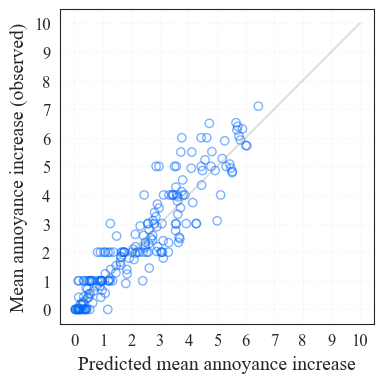

In [73]:
fig, ax = plt.subplots(figsize=(4, 4))
ax.plot([0, 10], [0, 10], "-", color='grey', alpha=0.25)                  # 1:1 line; use the response's range
ax.scatter(fit_am_detect2.table.predicted, fit_am_detect.table.observed, alpha=0.5, edgecolors=mycolours[0],
           facecolor='none')
ax.grid(which='major', color='grey', alpha=0.05, linestyle='--')
ax.set(xticks=range(0, 11), yticks=range(0, 11))
ax.set_xlabel("Predicted mean annoyance increase"); ax.set_ylabel("Mean annoyance increase (observed)")



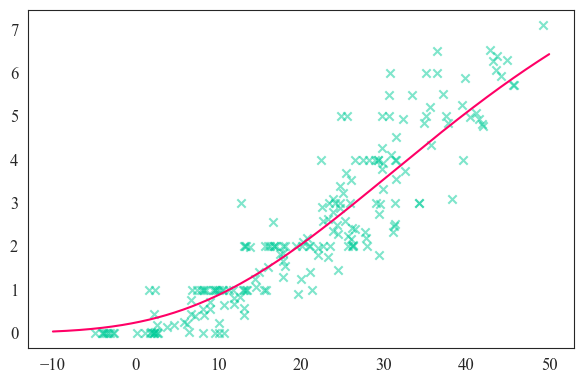

In [ ]:

grid = pd.DataFrame(np.linspace(-10, 50, 1000), columns=['Detect0p5dBIntEx50MaxLR'])
grid['PartSharpvBSHM05Ex'] = np.median(dataByStimTestNoAmb.loc[:, 'PartSharpvBSHM05Ex'])
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(dataByStimTestNoAmb.loc[:, 'Detect0p5dBIntEx50MaxLR'],
           dataByStimTestNoAmb.loc[:, 'dAnnoyanceMedian'],
           alpha=0.5, color=mycolours[1], marker='x')

ax.plot(grid['Detect0p5dBIntEx50MaxLR'], fit_am_detect2.predict(grid), color=mycolours[2])
plt.show()